# Sentiment Analysis on IMDb Reviews

This project classifies movie reviews as positive or negative using
TF-IDF and machine learning classifiers.

## 1. Load and Inspect the Dataset

Load the dataset and inspect its size, missing values, sentiment
distribution, and sample reviews.

In [33]:
import pandas as pd

df = pd.read_csv("data/IMDB Dataset.csv")

print("Dataset shape(rows, columns):", df.shape)

print("\nMissing values per column: ")
print(df.isna().sum())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

Dataset shape(rows, columns): (50000, 2)

Missing values per column: 
review       0
sentiment    0
dtype: int64

Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


## 2. Check Data Quality

Check duplicate reviews and sentiment labels before preprocessing.
Remove missing records and repeated reviews to prepare the dataset.

In [34]:
print("Sentiment labels :", df['sentiment'].unique())

print("Duplicate reviews:", df.duplicated(subset=["review"]).sum())

df = df.dropna(subset=["review", "sentiment"]).copy()

df = df.drop_duplicates(subset=["review"]).reset_index(drop=True)

# Check the dataset size and class distribution after cleaning.
print("\nDataset shape after cleaning:", df.shape)
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

Sentiment labels : <StringArray>
['positive', 'negative']
Length: 2, dtype: str
Duplicate reviews: 418

Dataset shape after cleaning: (49582, 2)

Sentiment distribution:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


## 3. Clean the Review Text

Convert reviews to lowercase, remove HTML tags, and normalize
punctuation and whitespace. Preserve negation words because
they help distinguish positive and negative sentiment.

In [35]:
import html
import re

def clean_review(text):
    text = html.unescape(text)
    text= text.lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.replace("’", "'")
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"n't\b", " not", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

print(clean_review("This isn't good"))
print(clean_review("I don't like it"))
print(clean_review("I wouldn't recommend it"))

df["clean_review"] = df["review"].apply(clean_review)
df[["review", "clean_review", "sentiment"]].head()

this is not good
i do not like it
i would not recommend it


,review,clean_review,sentiment
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,a wonderful little production the filming tech...,positive
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,basically there s a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei s love in the time of money is a...,positive


## 4. Remove Stopwords and Finalize Preprocessing

Remove common English stopwords while preserving negation words
such as **no**, **not**, and **nor**, which help identify sentiment.

After preprocessing, remove empty reviews and duplicate cleaned
reviews to prepare the dataset for the train/test split.

In [36]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = set(ENGLISH_STOP_WORDS) -  {"no", "not", "nor", "never"}

def remove_stopwords(text):
    return " ".join(
        word for word in text.split()
        if word not in stop_words
    )

df['clean_review'] = df['clean_review'].apply(remove_stopwords)

#  duplicates & empty reviews remove
df = df[df['clean_review'].str.strip().ne("")].copy()
df = df.drop_duplicates(subset=['clean_review']).reset_index(drop=True)

print("Dataset Shape:" , df.shape)

df[["review", "clean_review", "sentiment"]].head()

Dataset Shape: (49575, 3)


,review,clean_review,sentiment
0,One of the other reviewers has mentioned that ...,reviewers mentioned watching just oz episode l...,positive
1,A wonderful little production. <br /><br />The...,wonderful little production filming technique ...,positive
2,I thought this was a wonderful way to spend ti...,thought wonderful way spend time hot summer we...,positive
3,Basically there's a family where a little boy ...,basically s family little boy jake thinks s zo...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei s love time money visually stunn...,positive


## 5. Split the Dataset

Split the cleaned reviews into 80% training data and 20% testing data.
Preserve the sentiment distribution in both sets using stratified sampling.

In [37]:
from sklearn.model_selection import train_test_split
X = df['clean_review']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state= 40,
    stratify=y
    )

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training reviews: 39660
Testing reviews: 9915

Training sentiment distribution:
sentiment
positive    19904
negative    19756
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
positive    4976
negative    4939
Name: count, dtype: int64


## 6. Extract Features Using TF-IDF

Convert cleaned reviews into numerical features using TF-IDF.
Fit the vectorizer only on training data, then transform both
training and testing data to prevent data leakage.

In [38]:
from sklearn.feature_extraction.text import TfidfVectorizer

tf_idf = TfidfVectorizer(
    max_features= 50000,
    ngram_range=(1,2),
    sublinear_tf= True
)

X_train_tfidf = tf_idf.fit_transform(X_train)
X_test_tfidf = tf_idf.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

Training feature shape: (39660, 50000)
Testing feature shape: (9915, 50000)


## 7. Train a Logistic Regression Classifier

Train a Logistic Regression model on the TF-IDF training features
to classify reviews as positive or negative.

In [39]:
from sklearn.linear_model import LogisticRegression

lr_modeel = LogisticRegression(
    max_iter= 1000,
    random_state= 40
)

lr_modeel.fit(X_train_tfidf,y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",40
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

## 8. Evaluate the Baseline Logistic Regression Model

Predict sentiment on the test set and evaluate the model using
accuracy, precision, recall, F1-score, and a confusion matrix.

Accuracy : 90.29%

Classification Report:
              precision    recall  f1-score   support

    negative     0.9121    0.8909    0.9014      4939
    positive     0.8941    0.9148    0.9043      4976

    accuracy                         0.9029      9915
   macro avg     0.9031    0.9028    0.9029      9915
weighted avg     0.9031    0.9029    0.9029      9915



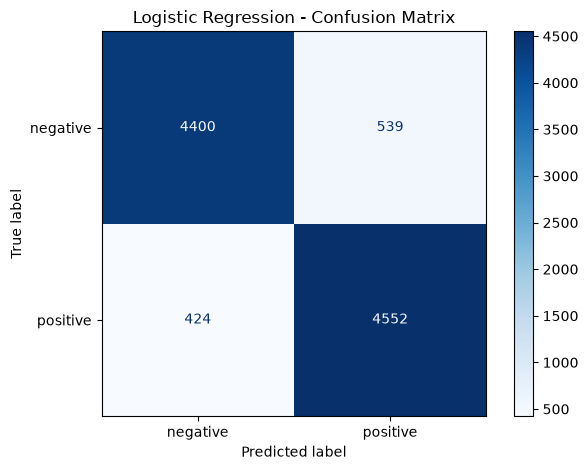

In [40]:
from sklearn.metrics import accuracy_score,classification_report,ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict sentiment for test reviews
y_pred = lr_modeel.predict(X_test_tfidf)

# Evaluate prediction aginst the actual  labels
print(f"Accuracy : {accuracy_score(y_test, y_pred):.2%}")

print("\nClassification Report:")
print(classification_report(y_test,y_pred, digits=4))

# visualize correct and incorrect predictions
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["negative", "positive"],
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


## 9. Tune Logistic Regression with Cross-Validation

Use three-fold cross-validation on the training data to select
the regularization parameter C. A pipeline fits TF-IDF separately
within each fold to prevent validation data leakage.

In [41]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=40
    ))
])

param_grid = {
    "model__C": [0.1, 1, 3, 10]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=40
)

search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    verbose=1
)

# Use training text directly; the pipeline handles TF-IDF
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print(f"Best mean validation accuracy: {search.best_score_:.2%}")

results = pd.DataFrame(search.cv_results_)
print(results[[
    "param_model__C",
    "mean_test_score",
    "std_test_score"
]].to_string(index=False))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'model__C': 10}
Best mean validation accuracy: 90.04%
 param_model__C  mean_test_score  std_test_score
            0.1         0.868255        0.002311
            1.0         0.896193        0.002635
            3.0         0.900277        0.002211
           10.0         0.900378        0.002487


## 10. Evaluate the Tuned Model

Evaluate the selected model on the test set and compare its
performance with the baseline Logistic Regression model.

Best parameters: {'model__C': 10}

Baseline test accuracy: 90.29%
Tuned test accuracy:    90.55%
Change: +0.26 percentage points

Tuned Model Classification Report:
              precision    recall  f1-score   support

    negative     0.9095    0.8998    0.9046      4939
    positive     0.9016    0.9112    0.9063      4976

    accuracy                         0.9055      9915
   macro avg     0.9056    0.9055    0.9055      9915
weighted avg     0.9055    0.9055    0.9055      9915



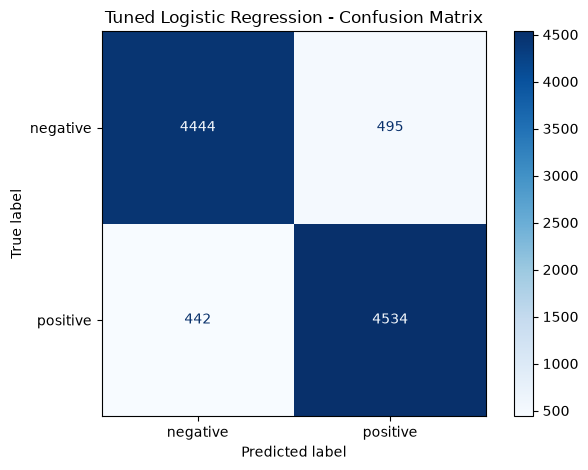

In [42]:
best_model = search.best_estimator_

# The pipeline transforms the text and predicts sentiment
y_pred_tuned = best_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, y_pred)
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print("Best parameters:", search.best_params_)
print(f"\nBaseline test accuracy: {baseline_accuracy:.2%}")
print(f"Tuned test accuracy:    {tuned_accuracy:.2%}")
print(
    f"Change: {(tuned_accuracy - baseline_accuracy) * 100:+.2f} "
    "percentage points"
)

print("\nTuned Model Classification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    digits=4
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    labels=["negative", "positive"],
    cmap="Blues",
    values_format="d"
)

plt.title("Tuned Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

## 11. Train Naive Bayes and Compare Models

Train a Multinomial Naive Bayes classifier using TF-IDF features.
Compare its test accuracy with the baseline and tuned Logistic
Regression models.

In [44]:
from sklearn.naive_bayes import MultinomialNB

# Train using the existing training features
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

# Predict test sentiment
y_pred_nb = nb_model.predict(X_test_tfidf)

print("Naive Bayes Classification Report:")
print(classification_report(y_test, y_pred_nb, digits=4))

# Compare all three models on the same test set
comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Tuned Logistic Regression",
        "Multinomial Naive Bayes"
    ],
    "Accuracy (%)": [
        baseline_accuracy * 100,
        tuned_accuracy * 100,
        accuracy_score(y_test, y_pred_nb) * 100
    ]
})

print("\nModel Comparison:")
print(comparison.round(2).to_string(index=False))

Naive Bayes Classification Report:
              precision    recall  f1-score   support

    negative     0.8862    0.8720    0.8791      4939
    positive     0.8750    0.8889    0.8819      4976

    accuracy                         0.8805      9915
   macro avg     0.8806    0.8805    0.8805      9915
weighted avg     0.8806    0.8805    0.8805      9915


Model Comparison:
                       Model  Accuracy (%)
Baseline Logistic Regression         90.29
   Tuned Logistic Regression         90.55
     Multinomial Naive Bayes         88.05


## 12. Visualize Frequent Words by Sentiment

Plot the 20 most frequent words in positive and negative training
reviews. These show word usage within each class, rather than
words exclusive to positive or negative sentiment.

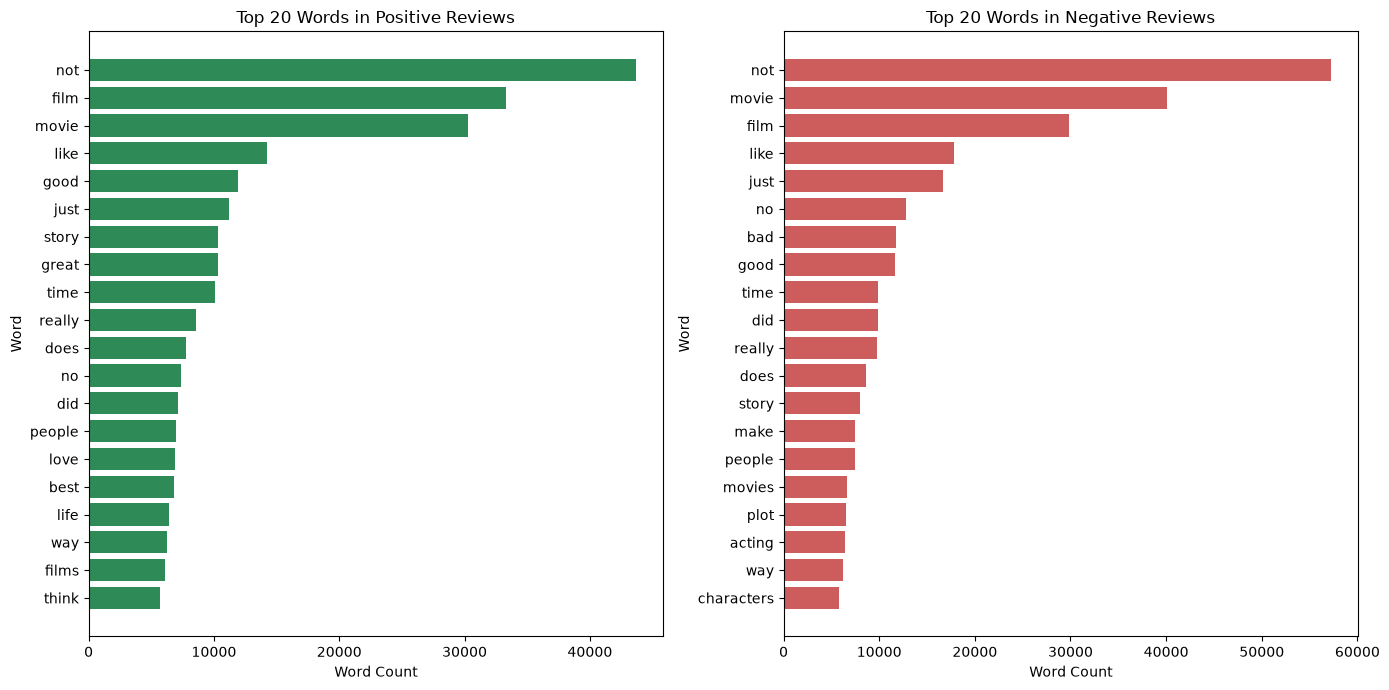

In [45]:
from collections import Counter

def get_top_words(reviews, top_n=20):
    counts = Counter()

    for review in reviews:
        counts.update(
            word for word in review.split()
            if len(word) > 1
        )

    return counts.most_common(top_n)


fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, sentiment, color in zip(
    axes,
    ["positive", "negative"],
    ["seagreen", "indianred"]
):
    reviews = X_train.loc[y_train == sentiment]
    top_words = get_top_words(reviews)

    words, counts = zip(*top_words)

    ax.barh(words, counts, color=color)
    ax.invert_yaxis()
    ax.set_title(f"Top 20 Words in {sentiment.title()} Reviews")
    ax.set_xlabel("Word Count")
    ax.set_ylabel("Word")

plt.tight_layout()
plt.show()

## 13. Conclusion

This project classified IMDb movie reviews as positive or negative
using text preprocessing, TF-IDF features, and machine learning.

### Test Results

| Model | Accuracy |
|---|---:|
| Baseline Logistic Regression | 90.29% |
| Tuned Logistic Regression | 90.55% |
| Multinomial Naive Bayes | 88.05% |

Three-fold cross-validation selected C=10 for Logistic Regression.
The tuned model achieved the highest test accuracy, improving
over the baseline by 0.26 percentage points.

Its F1-scores were 90.46% for negative reviews and 90.63% for
positive reviews, showing similar performance across both classes.

Word-frequency charts showed common words within each sentiment
class. Frequent words were not necessarily sentiment-specific.

### Limitations

The evaluation used a single train/test split. Performance on
other review domains, such as product reviews, has not been tested.
Sarcasm and context-dependent sentiment may also be challenging.

## 14. Save the Final Model

Save the tuned TF-IDF and Logistic Regression pipeline using
Joblib so it can be loaded in the Streamlit app without retraining.

In [46]:
import joblib

joblib.dump(best_model, "sentiment_model.joblib")

print("Model saved successfully.")

Model saved successfully.
